<h2>Лабораторна робота №4 «Model Selection and Hyperparameter Tuning»</h2>

In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_curve, RocCurveDisplay)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


import time
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.inspection import permutation_importance

<h3>1. Завантажити та підготувати дані для навчання</h3>

In [15]:
train_df = pd.read_csv('application_train.csv')
test_df = pd.read_csv('application_test.csv')

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()

Train shape: (307511, 122)
Test shape: (48744, 121)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Аналіз розподілів числових та категоріальних ознак

count       307511.0
mean        168798.0
std         237123.0
min          25650.0
25%         112500.0
50%         147150.0
75%         202500.0
max      117000000.0
Name: AMT_INCOME_TOTAL, dtype: float64


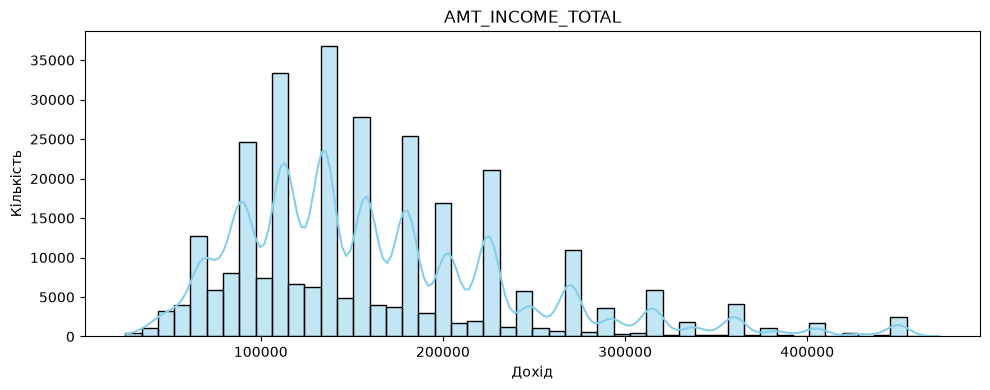

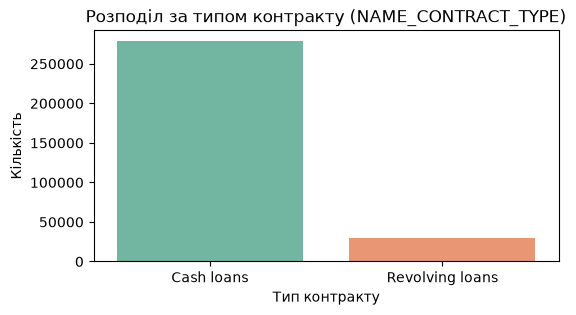

In [16]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = train_df.select_dtypes(include=['object', 'str']).columns.tolist()

income = train_df['AMT_INCOME_TOTAL']
print(income.describe().round(0))

fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(income[income <= income.quantile(0.99)], bins=50, kde=True, color='skyblue', ax=ax)
ax.set_title('AMT_INCOME_TOTAL')
ax.set_xlabel('Дохід')
ax.set_ylabel('Кількість')

plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 3))
sns.countplot(data=train_df, x='NAME_CONTRACT_TYPE', hue='NAME_CONTRACT_TYPE', palette='Set2', legend=False)
plt.title('Розподіл за типом контракту (NAME_CONTRACT_TYPE)')
plt.xlabel('Тип контракту')
plt.ylabel('Кількість')
plt.show()

аналіз пропущених значень;


In [17]:
missing_data = train_df.isnull().mean() * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

print(f"Загальна кількість колонок із пропусками: {len(missing_data)}")
print("\nТОП-10 колонок із найбільшою кількістю пропусків (%):")
print(missing_data.head(10))

Загальна кількість колонок із пропусками: 67

ТОП-10 колонок із найбільшою кількістю пропусків (%):
COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_AVG              69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
dtype: float64


аналіз збалансованості класів;



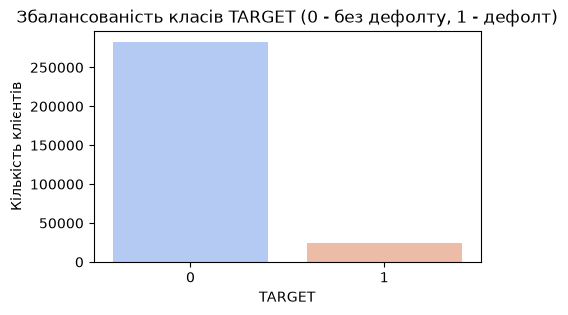

In [18]:
target_counts = train_df['TARGET'].value_counts()
target_percent = train_df['TARGET'].value_counts(normalize=True) * 100

plt.figure(figsize=(5, 3))
sns.countplot(data=train_df, x='TARGET', hue='TARGET', palette='coolwarm', legend=False)
plt.title('Збалансованість класів TARGET (0 - без дефолту, 1 - дефолт)')
plt.xlabel('TARGET')
plt.ylabel('Кількість клієнтів')
plt.show()

дослідження зв'язку окремих ознак із цільовою змінною;


ТОП-5 ознак з найбільшою позитивною кореляцією:
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: float64

ТОП-5 ознак з найбільшою негативною кореляцією:
EXT_SOURCE_3    -0.178919
EXT_SOURCE_2    -0.160472
EXT_SOURCE_1    -0.155317
DAYS_EMPLOYED   -0.044932
FLOORSMAX_AVG   -0.044003
Name: TARGET, dtype: float64


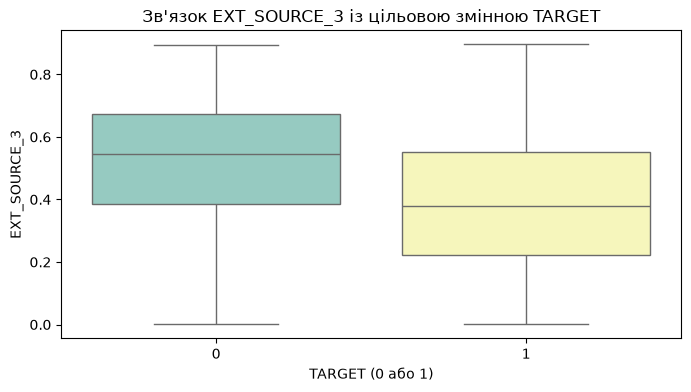

In [19]:
correlations = train_df[numeric_cols].corr()['TARGET'].sort_values()

print("ТОП-5 ознак з найбільшою позитивною кореляцією:")
print(correlations.tail(5))
print("\nТОП-5 ознак з найбільшою негативною кореляцією:")
print(correlations.head(5))

plt.figure(figsize=(8, 4))
sns.boxplot(data=train_df, x='TARGET', y='EXT_SOURCE_3', hue='TARGET', palette='Set3', legend =False)
plt.title('Зв\'язок EXT_SOURCE_3 із цільовою змінною TARGET')
plt.xlabel('TARGET (0 або 1)')
plt.ylabel('EXT_SOURCE_3')
plt.show()

пошук потенційно корисних закономірностей для побудови моделі.


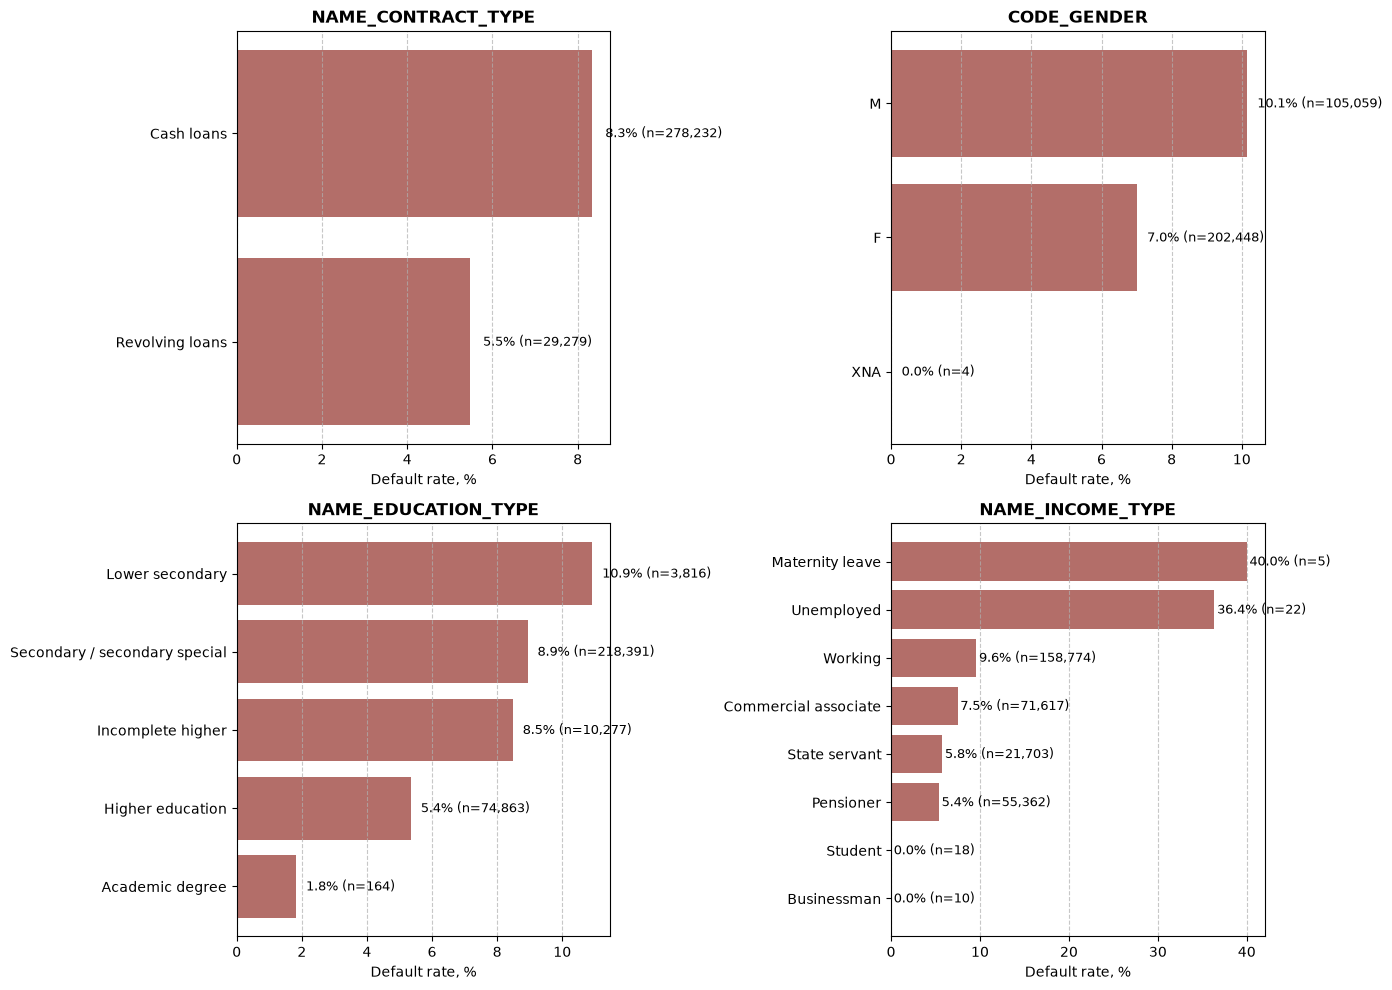

In [20]:
cat_cols = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten() 
for i, col in enumerate(cat_cols):
    ax = axes[i]
    
    stats = train_df.groupby(col, observed=True)['TARGET'].agg(
        rate=lambda x: x.mean() * 100,
        n='count'
    ).reset_index()
    
    stats = stats.sort_values('rate', ascending=True)
    
    bars = ax.barh(stats[col], stats['rate'], color='#a6554f', alpha=0.85)
    
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Default rate, %')
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    
    for bar, (_, row) in zip(bars, stats.iterrows()):
        width = bar.get_width()
        ax.text(
            width + 0.3,
            bar.get_y() + bar.get_height() / 2,
            f"{row['rate']:.1f}% (n={row['n']:,})",
            va='center',
            ha='left',
            fontsize=9,
            color='black'
        )

plt.tight_layout()
plt.show()

In [21]:
def add_features(df):
    df_new = df.copy()

    df_new['DAYS_EMPLOYED_ANOM'] = (df_new['DAYS_EMPLOYED'] == 365243).astype(int)
    df_new['DAYS_EMPLOYED'] = df_new['DAYS_EMPLOYED'].replace(365243, np.nan)

    df_new['CREDIT_INCOME_RATIO'] = df_new['AMT_CREDIT'] / (df_new['AMT_INCOME_TOTAL'] + 1e-5)
    df_new['ANNUITY_INCOME_RATIO'] = df_new['AMT_ANNUITY'] / (df_new['AMT_INCOME_TOTAL'] + 1e-5)
    df_new['CREDIT_TERM'] = df_new['AMT_CREDIT'] / (df_new['AMT_ANNUITY'] + 1e-5)
    df_new['AGE_YEARS'] = df_new['DAYS_BIRTH'] / -365.25
    df_new['EMPLOYED_YEARS'] = df_new['DAYS_EMPLOYED'] / -365.25
    df_new['EMPLOYED_TO_AGE_RATIO'] = df_new['EMPLOYED_YEARS'] / df_new['AGE_YEARS']

    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_new['EXT_SOURCE_MEAN'] = df_new[ext_cols].mean(axis=1)
    df_new['EXT_SOURCE_STD'] = df_new[ext_cols].std(axis=1).fillna(0)
    df_new['EXT_SOURCE_MISSING_CNT'] = df_new[ext_cols].isnull().sum(axis=1)

    education_mapping = {
        'Lower secondary': 1,
        'Secondary / secondary special': 2,
        'Incomplete higher': 3,
        'Higher education': 4,
        'Academic degree': 5
    }
    df_new['EDUCATION_RANK'] = df_new['NAME_EDUCATION_TYPE'].map(education_mapping)

    return df_new


X = train_df.drop(columns=['SK_ID_CURR', 'TARGET'])
y = train_df['TARGET']
x_test_final = test_df.drop(columns=['SK_ID_CURR'])

X_engineered = add_features(X)
x_test_final_engineered = add_features(x_test_final)
    

MISSING_THRESHOLD = 0.40
KEEP_ALWAYS = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

missing_share = X_engineered.isnull().mean()
cols_to_drop = [c for c in missing_share[missing_share > MISSING_THRESHOLD].index if c not in KEEP_ALWAYS]

X_engineered = X_engineered.drop(columns=cols_to_drop)
x_test_final_engineered = x_test_final_engineered.reindex(columns=X_engineered.columns)

assert list(X_engineered.columns) == list(x_test_final_engineered.columns)

print("Розмірність до Feature Engineering:   ", X.shape)
print("Розмірність після Feature Engineering:", X_engineered.shape)
print("Видалено колонок із пропусками >40%:  ", len(cols_to_drop))
print("Розмірність test після Feature Engineering:            ", x_test_final_engineered.shape)

Розмірність до Feature Engineering:    (307511, 120)
Розмірність після Feature Engineering: (307511, 83)
Видалено колонок із пропусками >40%:   48
Розмірність test після Feature Engineering:             (48744, 83)


In [22]:
num_cols = X_engineered.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_engineered.select_dtypes(exclude=[np.number, 'bool']).columns.tolist()

print("Числових ознак:", len(num_cols))
print("Категоріальних ознак:", len(cat_cols))

Числових ознак: 71
Категоріальних ознак: 12


<h3>4. Розділити навчальні дані на навчальну та валідаційну вибірки (train-validation split)</h3>

In [23]:
X_train, X_val, y_train, y_val = train_test_split(
    X_engineered, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

<h3>5. Постановка експерименту з порівняння моделей</h3>


In [24]:
RANDOM_STATE = 42

TUNE_SAMPLE = 50000
CV_FOLDS    = 5
N_ITER      = 15
PERM_SAMPLE = 15000

def make_preprocessor(scale=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer(transformers=[
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
    ])

BASE_MODELS = {
    'Logistic Regression': (True,  LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    'Decision Tree':       (False, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    'Random Forest':       (False, RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
    'Gradient Boosting':   (False, HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    'Neural Network':      (True,  MLPClassifier(hidden_layer_sizes=(100,), early_stopping=True, n_iter_no_change=10,
                                                  max_iter=200, random_state=RANDOM_STATE)),
}

def make_pipeline(name):
    scale, clf = BASE_MODELS[name]
    return Pipeline([('preprocessor', make_preprocessor(scale)), ('classifier', clone(clf))])

def fit_and_score(pipe, label):
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0
    train_auc = roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1])
    val_proba = pipe.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, val_proba)
    return {'model': label, 'train_auc': train_auc, 'val_auc': val_auc, 'fit_time_s': fit_time}, val_proba

print('Train:', X_train.shape, '| Val:', X_val.shape)
print('Частка дефолтів у train: %.2f%%' % (100 * y_train.mean()))

Train: (246008, 83) | Val: (61503, 83)
Частка дефолтів у train: 8.07%


<h3>6. Навчання моделей зі стандартними гіперпараметрами та оцінка на валідації (ROC-AUC)</h3>

In [25]:
baseline_rows, baseline_proba, baseline_pipes = [], {}, {}
for name in BASE_MODELS:
    print(f'>>> {name} ...', end=' ', flush=True)
    pipe = make_pipeline(name)
    row, proba = fit_and_score(pipe, name)
    baseline_rows.append(row); baseline_proba[name] = proba; baseline_pipes[name] = pipe
    print(f"val AUC = {row['val_auc']:.4f} (train AUC = {row['train_auc']:.4f}, {row['fit_time_s']:.1f} c)")

baseline_df = pd.DataFrame(baseline_rows).set_index('model')
baseline_df['overfit_gap'] = baseline_df['train_auc'] - baseline_df['val_auc']
baseline_df.round(4)

>>> Logistic Regression ... val AUC = 0.7505 (train AUC = 0.7504, 13.9 c)
>>> Decision Tree ... val AUC = 0.5421 (train AUC = 1.0000, 49.7 c)
>>> Random Forest ... val AUC = 0.7277 (train AUC = 1.0000, 60.5 c)
>>> Gradient Boosting ... val AUC = 0.7654 (train AUC = 0.8017, 27.1 c)
>>> Neural Network ... val AUC = 0.7539 (train AUC = 0.7661, 572.7 c)


,train_auc,val_auc,fit_time_s,overfit_gap
model,,,,
Logistic Regression,0.7504,0.7505,13.9272,-0.0001
Decision Tree,1.0000,0.5421,49.6775,0.4579
Random Forest,1.0000,0.7277,60.4993,0.2723
Gradient Boosting,0.8017,0.7654,27.0501,0.0364
Neural Network,0.7661,0.7539,572.7109,0.0121


<h3>7. Підбір оптимальних гіперпараметрів (Randomized Search + Stratified K-Fold CV)</h3>

In [26]:
PARAM_DISTS = {
    'Logistic Regression': {
        'classifier__C': loguniform(1e-3, 1e1),
        'classifier__class_weight': [None, 'balanced'],
    },
    'Decision Tree': {
        'classifier__max_depth': randint(3, 16),
        'classifier__min_samples_leaf': randint(20, 500),
        'classifier__min_samples_split': randint(2, 200),
        'classifier__max_features': [None, 'sqrt', 0.5],
        'classifier__class_weight': [None, 'balanced'],
    },
    'Random Forest': {
        'classifier__n_estimators': [100, 200, 300],
        'classifier__max_depth': [6, 8, 10, 12, 16, None],
        'classifier__min_samples_leaf': randint(20, 200),
        'classifier__max_features': ['sqrt', 0.3, 0.5],
        'classifier__class_weight': [None, 'balanced_subsample'],
    },
    'Gradient Boosting': {
        'classifier__learning_rate': loguniform(0.02, 0.2),
        'classifier__max_iter': [200, 300, 500],
        'classifier__max_leaf_nodes': randint(8, 64),
        'classifier__min_samples_leaf': randint(20, 300),
        'classifier__l2_regularization': loguniform(1e-3, 1e1),
        'classifier__class_weight': [None, 'balanced'],
    },
    'Neural Network': {
        'classifier__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
        'classifier__alpha': loguniform(1e-5, 1e-1),
        'classifier__learning_rate_init': loguniform(1e-4, 1e-2),
        'classifier__batch_size': [256, 512, 1024],
    },
}

if TUNE_SAMPLE < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=TUNE_SAMPLE,
                                            stratify=y_train, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train, y_train

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

tuned_rows, tuned_proba, tuned_pipes, best_params, search_info = [], {}, {}, {}, {}
for name in BASE_MODELS:
    print(f'\n===== {name} =====')
    search = RandomizedSearchCV(make_pipeline(name), PARAM_DISTS[name], n_iter=N_ITER, scoring='roc_auc',
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=False, verbose=1)
    t0 = time.time()
    search.fit(X_tune, y_tune)
    search_time = time.time() - t0
    best_params[name] = search.best_params_
    search_info[name] = {'cv_auc': search.best_score_, 'search_time_s': search_time}
    print('Найкращі параметри:', {k.replace('classifier__', ''): (round(float(v), 5) if isinstance(v, (float, np.floating)) else v)
                                  for k, v in search.best_params_.items()})
    print(f'CV AUC = {search.best_score_:.4f}, час пошуку = {search_time:.0f} c')

    pipe = make_pipeline(name).set_params(**search.best_params_)
    row, proba = fit_and_score(pipe, name)
    tuned_rows.append(row); tuned_proba[name] = proba; tuned_pipes[name] = pipe
    print(f"Val AUC (tuned) = {row['val_auc']:.4f}, train AUC = {row['train_auc']:.4f}")


===== Logistic Regression =====
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Найкращі параметри: {'C': 0.12563, 'class_weight': None}
CV AUC = 0.7473, час пошуку = 80 c
Val AUC (tuned) = 0.7504, train AUC = 0.7503

===== Decision Tree =====
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Найкращі параметри: {'class_weight': None, 'max_depth': 9, 'max_features': 0.5, 'min_samples_leaf': 478, 'min_samples_split': 89}
CV AUC = 0.7137, час пошуку = 43 c
Val AUC (tuned) = 0.7297, train AUC = 0.7475

===== Random Forest =====
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Найкращі параметри: {'class_weight': 'balanced_subsample', 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 68, 'n_estimators': 300}
CV AUC = 0.7430, час пошуку = 1291 c
Val AUC (tuned) = 0.7526, train AUC = 0.8270

===== Gradient Boosting =====
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Найкращі параметри: {'class_weight': 'balanced', 'l2_regularizat

<h3>8. Порівняння результатів</h3>

In [27]:
tuned_df = pd.DataFrame(tuned_rows).set_index('model')
tuned_df['overfit_gap'] = tuned_df['train_auc'] - tuned_df['val_auc']

comparison = pd.DataFrame({
    'val_AUC_default':  baseline_df['val_auc'],
    'val_AUC_tuned':    tuned_df['val_auc'],
    'AUC_gain':         tuned_df['val_auc'] - baseline_df['val_auc'],
    'CV_AUC (subsample)': pd.Series({k: v['cv_auc'] for k, v in search_info.items()}),
    'gap_default':      baseline_df['overfit_gap'],
    'gap_tuned':        tuned_df['overfit_gap'],
    'fit_time_default_s': baseline_df['fit_time_s'],
    'fit_time_tuned_s':   tuned_df['fit_time_s'],
    'search_time_s':      pd.Series({k: v['search_time_s'] for k, v in search_info.items()}),
}).sort_values('val_AUC_tuned', ascending=False)
comparison.round(4)

,val_AUC_default,val_AUC_tuned,AUC_gain,CV_AUC (subsample),gap_default,gap_tuned,fit_time_default_s,fit_time_tuned_s,search_time_s
Gradient Boosting,0.7654,0.7659,0.0006,0.7503,0.0364,0.0110,27.0501,62.4437,443.4948
Random Forest,0.7277,0.7526,0.0248,0.7430,0.2723,0.0745,60.4993,120.1500,1291.2489
Logistic Regression,0.7505,0.7504,-0.0001,0.7473,-0.0001,-0.0002,13.9272,10.1313,80.1820
Neural Network,0.7539,0.7499,-0.0040,0.7390,0.0121,0.0145,572.7109,416.9639,178.5865
Decision Tree,0.5421,0.7297,0.1876,0.7137,0.4579,0.0179,49.6775,12.7928,42.6932


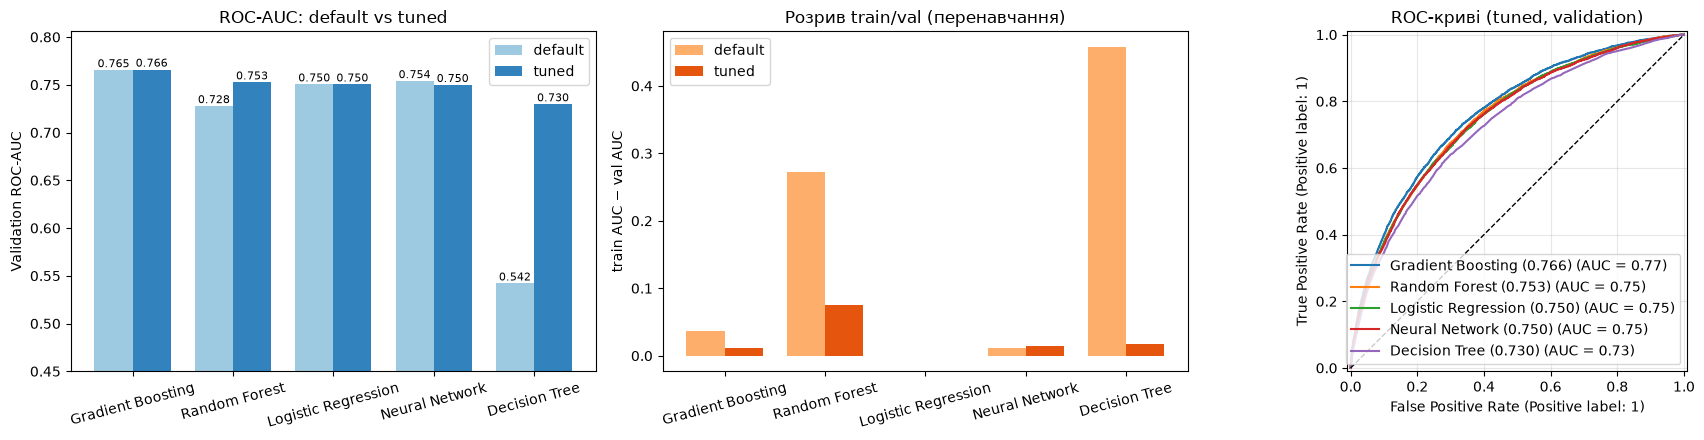

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

order = comparison.index.tolist()
x = np.arange(len(order)); w = 0.38
axes[0].bar(x - w/2, comparison['val_AUC_default'], w, label='default', color='#9ecae1')
axes[0].bar(x + w/2, comparison['val_AUC_tuned'], w, label='tuned', color='#3182bd')
for i, m in enumerate(order):
    axes[0].text(i - w/2, comparison.loc[m, 'val_AUC_default'] + 0.003, f"{comparison.loc[m, 'val_AUC_default']:.3f}", ha='center', fontsize=8)
    axes[0].text(i + w/2, comparison.loc[m, 'val_AUC_tuned'] + 0.003, f"{comparison.loc[m, 'val_AUC_tuned']:.3f}", ha='center', fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=15)
axes[0].set_ylim(0.45, max(0.8, comparison['val_AUC_tuned'].max() + 0.04))
axes[0].set_ylabel('Validation ROC-AUC'); axes[0].set_title('ROC-AUC: default vs tuned'); axes[0].legend()

axes[1].bar(x - w/2, comparison['gap_default'], w, label='default', color='#fdae6b')
axes[1].bar(x + w/2, comparison['gap_tuned'], w, label='tuned', color='#e6550d')
axes[1].set_xticks(x); axes[1].set_xticklabels(order, rotation=15)
axes[1].set_ylabel('train AUC − val AUC'); axes[1].set_title('Розрив train/val (перенавчання)'); axes[1].legend()

for name in order:
    RocCurveDisplay.from_predictions(y_val, tuned_proba[name], name=f"{name} ({comparison.loc[name, 'val_AUC_tuned']:.3f})", ax=axes[2])
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('ROC-криві (tuned, validation)'); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

<h3>9. Важливість ознак та інтерпретація моделей</h3>

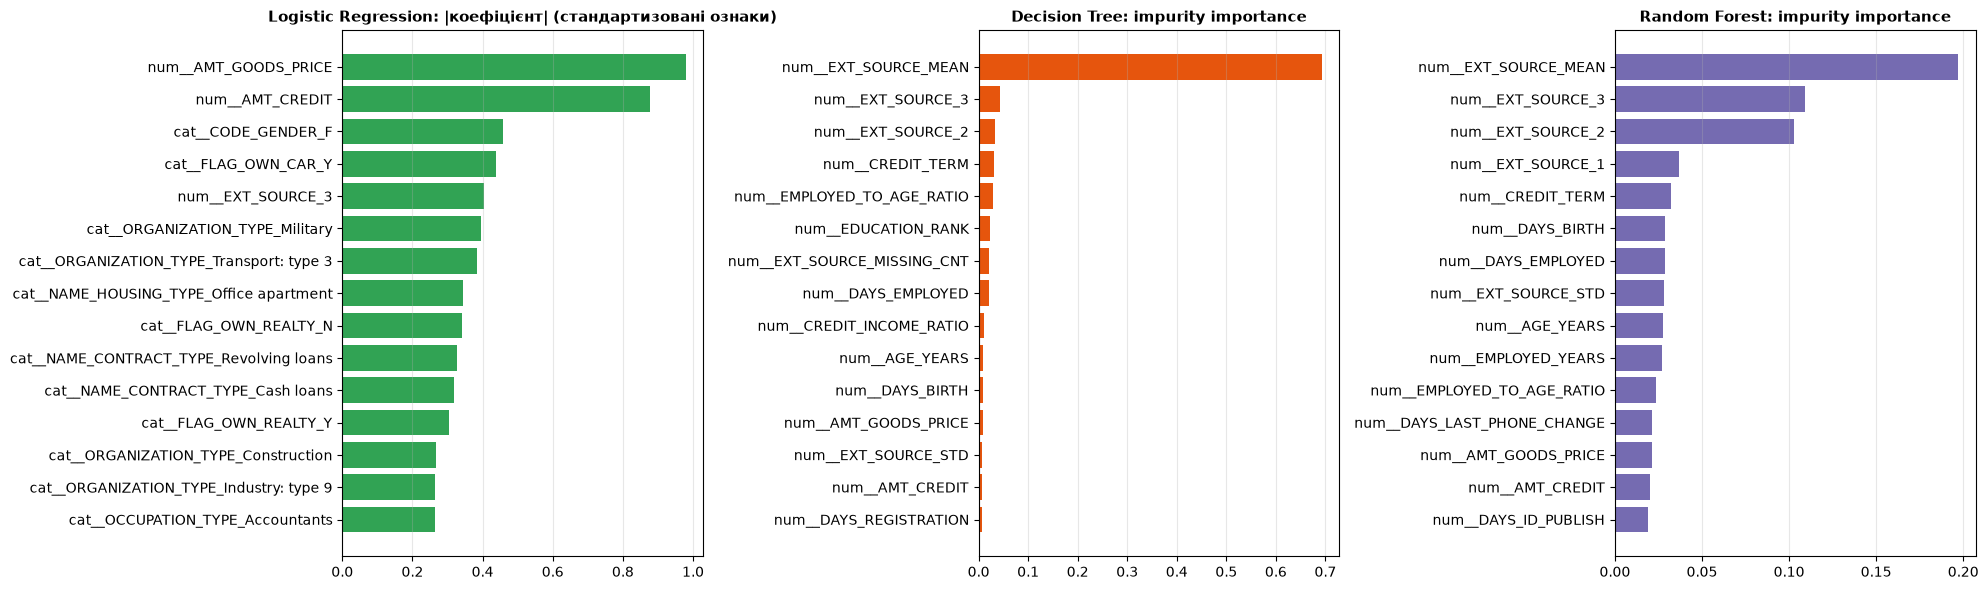

Logistic Regression: ознаки, що найбільше ЗБІЛЬШУЮТЬ ризик дефолту:
num__AMT_CREDIT                             0.877
cat__ORGANIZATION_TYPE_Transport: type 3    0.385
cat__ORGANIZATION_TYPE_Construction         0.267
cat__OCCUPATION_TYPE_Low-skill Laborers     0.223
cat__ORGANIZATION_TYPE_Self-employed        0.165

Logistic Regression: ознаки, що найбільше ЗНИЖУЮТЬ ризик дефолту:
num__AMT_GOODS_PRICE              -0.979
cat__CODE_GENDER_F                -0.458
cat__FLAG_OWN_CAR_Y               -0.439
num__EXT_SOURCE_3                 -0.403
cat__ORGANIZATION_TYPE_Military   -0.395


In [29]:
def top_bar(ax, series, title, n=15, color='#3182bd'):
    s = series.sort_values(ascending=False).head(n)[::-1]
    ax.barh(s.index, s.values, color=color)
    ax.set_title(title, fontsize=11, fontweight='bold'); ax.grid(axis='x', alpha=0.3)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

lr_pipe = tuned_pipes['Logistic Regression']
lr_names = lr_pipe.named_steps['preprocessor'].get_feature_names_out()
lr_coef = pd.Series(lr_pipe.named_steps['classifier'].coef_[0], index=lr_names)
top_bar(axes[0], lr_coef.abs(), 'Logistic Regression: |коефіцієнт| (стандартизовані ознаки)', color='#31a354')

for ax, name, col in zip(axes[1:], ['Decision Tree', 'Random Forest'], ['#e6550d', '#756bb1']):
    p = tuned_pipes[name]
    names = p.named_steps['preprocessor'].get_feature_names_out()
    imp = pd.Series(p.named_steps['classifier'].feature_importances_, index=names)
    top_bar(ax, imp, f'{name}: impurity importance', color=col)
plt.tight_layout(); plt.show()

print('Logistic Regression: ознаки, що найбільше ЗБІЛЬШУЮТЬ ризик дефолту:')
print(lr_coef.sort_values(ascending=False).head(5).round(3).to_string())
print('\nLogistic Regression: ознаки, що найбільше ЗНИЖУЮТЬ ризик дефолту:')
print(lr_coef.sort_values().head(5).round(3).to_string())

C:\Users\Анастасія\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Logistic Regression: 27 c
Decision Tree: 14 c
Random Forest: 113 c
Gradient Boosting: 143 c
Neural Network: 17 c


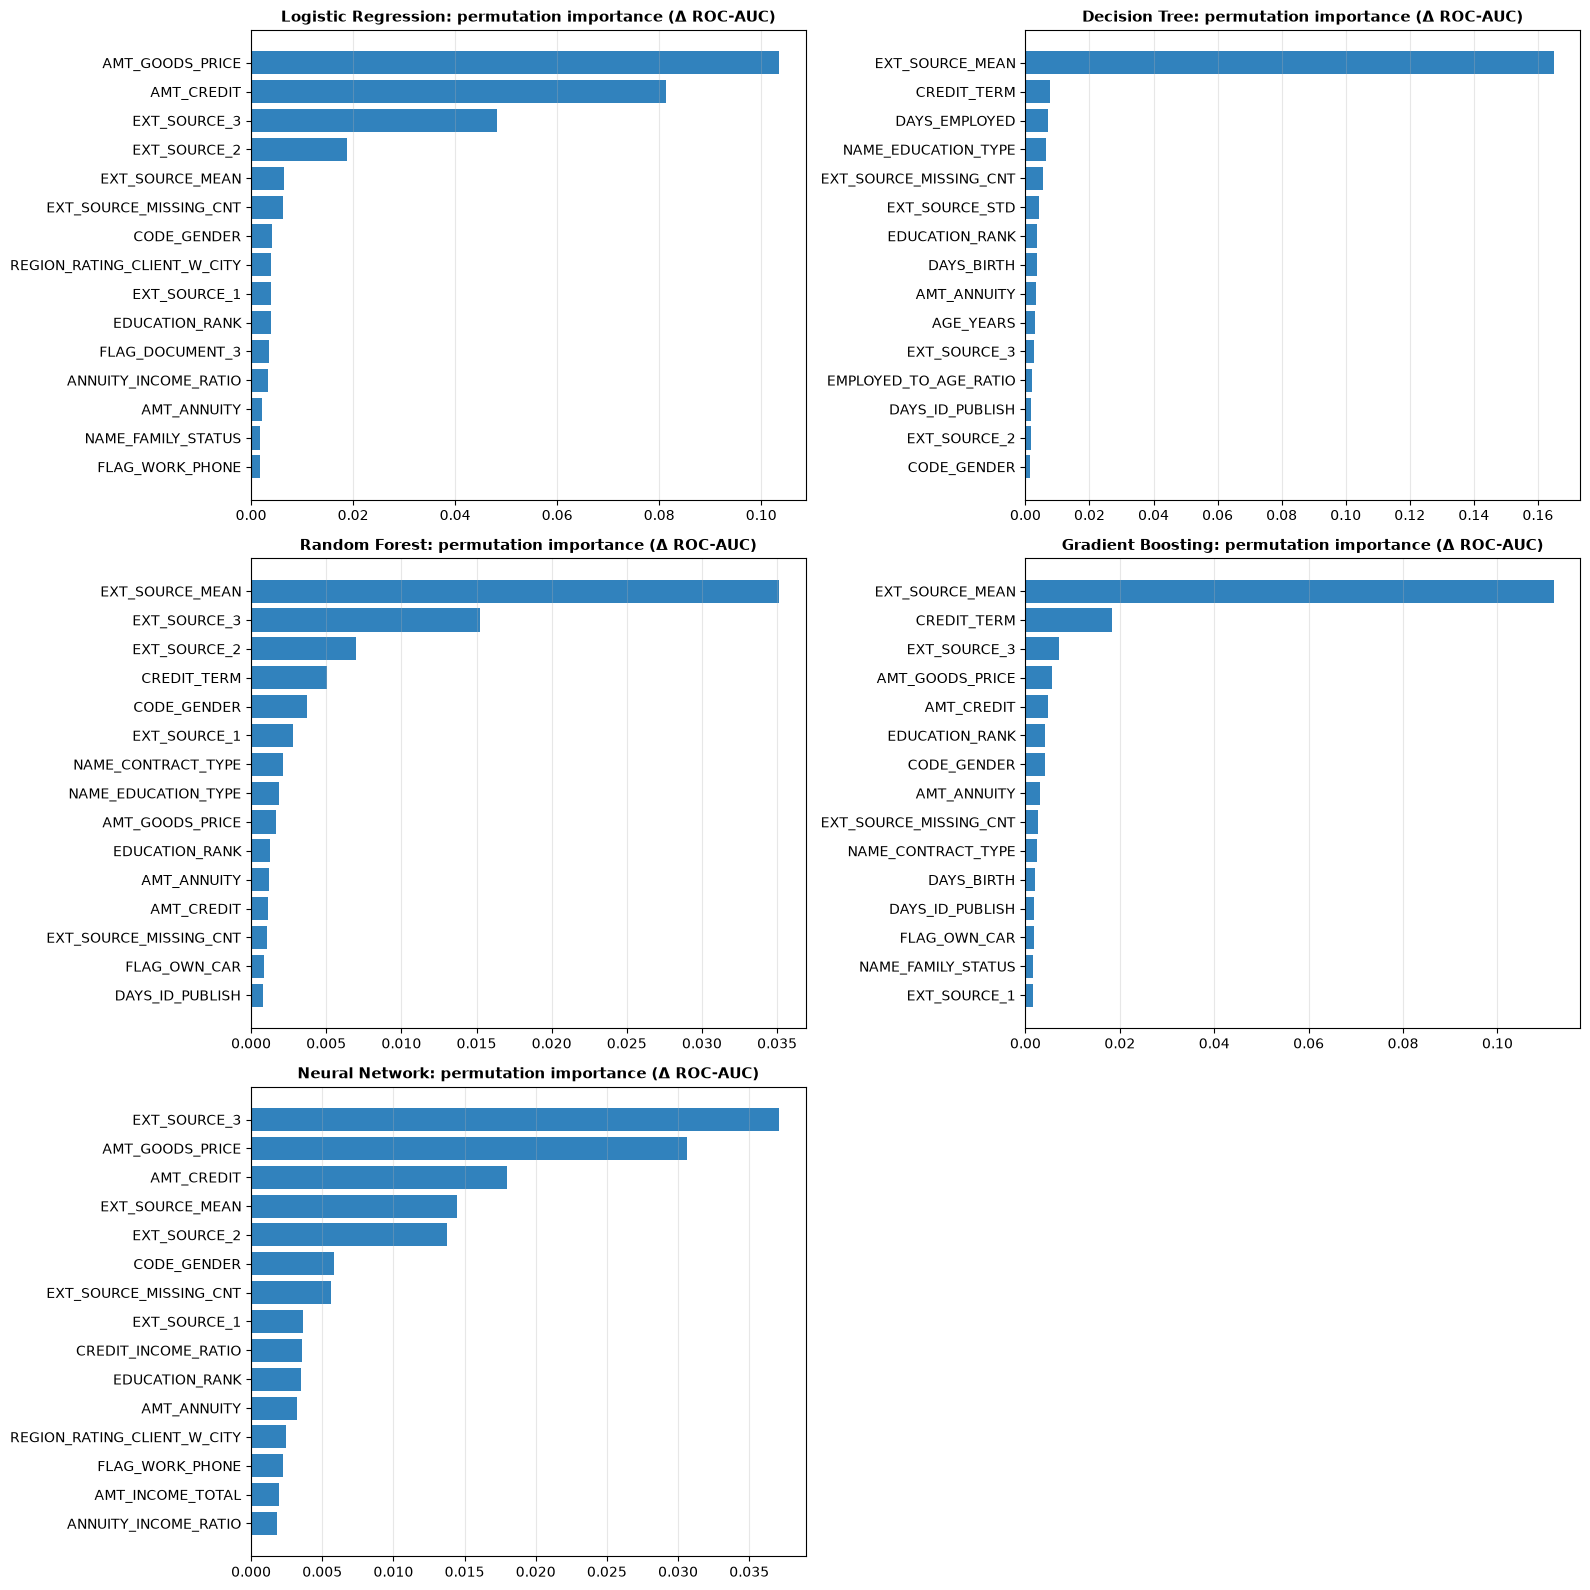


ТОП-8 ознак за permutation importance:


,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,Neural Network
1,AMT_GOODS_PRICE,EXT_SOURCE_MEAN,EXT_SOURCE_MEAN,EXT_SOURCE_MEAN,EXT_SOURCE_3
2,AMT_CREDIT,CREDIT_TERM,EXT_SOURCE_3,CREDIT_TERM,AMT_GOODS_PRICE
3,EXT_SOURCE_3,DAYS_EMPLOYED,EXT_SOURCE_2,EXT_SOURCE_3,AMT_CREDIT
4,EXT_SOURCE_2,NAME_EDUCATION_TYPE,CREDIT_TERM,AMT_GOODS_PRICE,EXT_SOURCE_MEAN
5,EXT_SOURCE_MEAN,EXT_SOURCE_MISSING_CNT,CODE_GENDER,AMT_CREDIT,EXT_SOURCE_2
6,EXT_SOURCE_MISSING_CNT,EXT_SOURCE_STD,EXT_SOURCE_1,EDUCATION_RANK,CODE_GENDER
7,CODE_GENDER,EDUCATION_RANK,NAME_CONTRACT_TYPE,CODE_GENDER,EXT_SOURCE_MISSING_CNT
8,REGION_RATING_CLIENT_W_CITY,DAYS_BIRTH,NAME_EDUCATION_TYPE,AMT_ANNUITY,EXT_SOURCE_1


In [30]:
rng = np.random.RandomState(RANDOM_STATE)
perm_idx = rng.choice(len(X_val), size=min(PERM_SAMPLE, len(X_val)), replace=False)
X_perm, y_perm = X_val.iloc[perm_idx], y_val.iloc[perm_idx]

perm_results = {}
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
for ax in axes.ravel()[len(BASE_MODELS):]:
    ax.axis('off')
for ax, name in zip(axes.ravel(), BASE_MODELS):
    t0 = time.time()
    r = permutation_importance(tuned_pipes[name], X_perm, y_perm, scoring='roc_auc',
                               n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=X_perm.columns)
    perm_results[name] = imp
    top_bar(ax, imp, f'{name}: permutation importance (Δ ROC-AUC)', color='#3182bd')
    print(f'{name}: {time.time() - t0:.0f} c')
plt.tight_layout(); plt.show()

perm_top = pd.DataFrame({n: s.sort_values(ascending=False).head(8).index.tolist() for n, s in perm_results.items()})
perm_top.index = range(1, len(perm_top) + 1)
print('\nТОП-8 ознак за permutation importance:')
perm_top

<h3>10. Висновки</h3>

In [31]:
best_name = comparison['val_AUC_tuned'].idxmax()
print(f"Найкраща модель за validation ROC-AUC: {best_name} ({comparison.loc[best_name, 'val_AUC_tuned']:.4f})")
print('\nВплив вибору моделі (tuned, validation AUC):')
for m, v in comparison['val_AUC_tuned'].items():
    print(f'  {m:22s} {v:.4f}')
print(f"  Різниця між найкращою і найгіршою: {comparison['val_AUC_tuned'].max() - comparison['val_AUC_tuned'].min():.4f}")
print('\nВплив підбору гіперпараметрів (приріст AUC відносно default):')
for m, v in comparison['AUC_gain'].items():
    print(f'  {m:22s} {v:+.4f}')
print('\nСкладність навчання (с): навчання з найкращими параметрами / повний пошук:')
for m in comparison.index:
    print(f"  {m:22s} {comparison.loc[m, 'fit_time_tuned_s']:7.1f} / {comparison.loc[m, 'search_time_s']:7.1f}")

Найкраща модель за validation ROC-AUC: Gradient Boosting (0.7659)

Вплив вибору моделі (tuned, validation AUC):
  Gradient Boosting      0.7659
  Random Forest          0.7526
  Logistic Regression    0.7504
  Neural Network         0.7499
  Decision Tree          0.7297
  Різниця між найкращою і найгіршою: 0.0363

Вплив підбору гіперпараметрів (приріст AUC відносно default):
  Gradient Boosting      +0.0006
  Random Forest          +0.0248
  Logistic Regression    -0.0001
  Neural Network         -0.0040
  Decision Tree          +0.1876

Складність навчання (с): навчання з найкращими параметрами / повний пошук:
  Gradient Boosting         62.4 /   443.5
  Random Forest            120.2 /  1291.2
  Logistic Regression       10.1 /    80.2
  Neural Network           417.0 /   178.6
  Decision Tree             12.8 /    42.7


<h3>11. Класифікація application_test.csv та формування submission-файлу</h3>

In [32]:
import os
final_pipe = make_pipeline(best_name).set_params(**best_params[best_name])
t0 = time.time()
final_pipe.fit(X_engineered, y)
print(f'Фінальна модель: {best_name}, навчання на {len(X_engineered)} рядках за {time.time() - t0:.0f} c')

test_proba = final_pipe.predict_proba(x_test_final_engineered)[:, 1]
submission = pd.DataFrame({'SK_ID_CURR': test_df['SK_ID_CURR'], 'TARGET': test_proba})
submission.to_csv('submission.csv', index=False)
print('submission.csv збережено:', submission.shape)

if os.path.exists('sample_submission.csv'):
    sample = pd.read_csv('sample_submission.csv')
    assert list(sample.columns) == list(submission.columns), 'Колонки не збігаються з sample_submission'
    assert len(sample) == len(submission) and (sample['SK_ID_CURR'].values == submission['SK_ID_CURR'].values).all(), 'ID не збігаються'
    print('Формат збігається з sample_submission.csv')
submission.head()

Фінальна модель: Gradient Boosting, навчання на 307511 рядках за 92 c
submission.csv збережено: (48744, 2)


,SK_ID_CURR,TARGET
0,100001,0.249375
1,100005,0.571649
2,100013,0.188058
3,100028,0.364763
4,100038,0.690886
